<div style="color:#3c4d5a; border-top: 6px solid #1f77b4; border-bottom: 6px solid #1f77b4; padding: 10px; text-align: center;">
<h1>Predicción de Demanda y Stock con Redes Neuronales Recurrentes (LSTM)</h1>
<h3>Práctica 2: Aprendizaje Profundo y Series Temporales</h3>
<p><strong>Estudiantes:</strong> Daniel Guanga, Alexys Guaman & Cinthya Ramón 
<strong>Asignatura:</strong> Aprendizaje Automático | Carrera de Computación<br>
<strong>Empresa del caso:</strong> Corporación Favorita (Supermercados La Favorita)<br>
<strong>Historial:</strong> 01/10/2025 – 30/09/2026 | <strong>Fecha:</strong> Octubre 2026</p>
</div>

**Objetivo:** predecir la **demanda diaria** de 10 productos con una LSTM y, a partir de ella, el **stock al cierre** con la regla de reposición de la tienda.

```
LSTM → demanda(t) → stock_cierre(t) = stock_inicio(t) − demanda(t)
```

**Estructura:**
0. Preparación del entorno
1. Generación del dataset
2. Fase 1: Análisis y preparación (EDA, Feature Engineering, secuencias)
3. Fase 2: Desarrollo y entrenamiento de modelos
4. Fase 3: Funciones de predicción
5. Predicciones personalizadas
6. Conclusiones
7. Referencias

Las explicaciones detalladas están en `docs/explicaciones_practica2.md`.

## 0. Preparación del entorno

In [1]:
# Librerías y reproducibilidad
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_DETERMINISTIC_OPS"] = "1"

from pathlib import Path
from functools import lru_cache
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import holidays
import joblib
import sklearn
import tensorflow as tf
from IPython.display import display

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

SEMILLA = 42
np.random.seed(SEMILLA)
tf.random.set_seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)

# Rutas relativas a la carpeta notebooks/
DATA = Path("../data")
MODELOS = Path("../models")
FIGURAS = Path("../figures")
TABLAS = Path("../tables")
for carpeta in (DATA, MODELOS, FIGURAS, TABLAS):
    carpeta.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False
})

def guardar_grafico(nombre):
    plt.tight_layout()
    plt.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight")
    plt.show()
    plt.close()

print(f"TensorFlow: {tf.__version__} | pandas: {pd.__version__} | scikit-learn: {sklearn.__version__}")
print(f"GPUs disponibles: {len(tf.config.list_physical_devices('GPU'))}")

TensorFlow: 2.21.0 | pandas: 3.0.2 | scikit-learn: 1.9.1


GPUs disponibles: 0


## 1. Generación del dataset

**Resumen:** 365 días (01/10/2025 – 30/09/2026), 3.650 registros, 10 productos en 6 categorías.

**Modificaciones y su justificación de negocio:**
- **Un año de historial:** así el modelo ve todos los feriados, la temporada navideña y los días de pago del año. Las predicciones se limitan a **60 días** después del último dato.
- **Feriados oficiales de Ecuador** (librería `holidays`): para medir cuánto cambian las compras en feriados y en sus vísperas.
- **Reposición con regla fija (s, S):** si el stock de cierre baja del punto de reorden, la mañana siguiente se repone hasta el nivel máximo. Así el stock depende de la demanda y se puede calcular.
- **Ventas ≤ stock disponible:** no se puede vender lo que no hay en percha.
- **Unidad comercial:** los productos empacados se venden por `unidad` (números enteros) y los productos a granel por `kg` (con decimales).

In [2]:
# Parámetros del escenario
FECHA_INICIO = "2025-10-01"
FECHA_FIN = "2026-09-30"
HORIZONTE_MAX = 60          # días máximos a predecir después del último dato

fechas = pd.date_range(FECHA_INICIO, FECHA_FIN, freq="D")
ultima_fecha = fechas[-1]

# Feriados oficiales de Ecuador (incluye el periodo de predicción)
feriados_ec = holidays.EC(years=range(fechas[0].year, fechas[-1].year + 2))
FERIADOS = pd.DatetimeIndex(sorted(feriados_ec.keys()))
VISPERAS = (FERIADOS - pd.Timedelta(days=1)).difference(FERIADOS)

def es_dia_pago(f):
    """Quincena (días 14-16) y fin de mes (últimos 3 días)."""
    f = pd.DatetimeIndex(f)
    return np.asarray(((f.day >= 14) & (f.day <= 16)) | (f.day >= f.days_in_month - 2))

def es_navidad(f):
    f = pd.DatetimeIndex(f)
    return np.asarray((f.month == 12) & (f.day >= 15))

# Catálogo: venta base diaria, vida útil del lote y precio referencial (USD)
catalogo = pd.DataFrame([
    ("103665", "Pan de Molde Blanco",        "Panadería",         "unidad", 35,   6,  2.10),
    ("105574", "Arroz Flor Blanco 1kg",      "Abarrotes",         "unidad", 40, 180,  1.20),
    ("108634", "Leche Entera Tetrapack 1L",  "Lácteos y Huevos",  "unidad", 45,  14,  1.05),
    ("108701", "Tomate Riñón Fresco",        "Frutas y Verduras", "kg",     30,   8,  1.30),
    ("114674", "Pollo Entero Fresco",        "Cárnicos",          "kg",     25,   5,  3.30),
    ("119024", "Huevos Blancos Empaque 12u", "Lácteos y Huevos",  "unidad", 30,  21,  2.40),
    ("121528", "Aceite Vegetal Palma 1L",    "Abarrotes",         "unidad", 20, 300,  2.60),
    ("123601", "Manzana Royal Gala",         "Frutas y Verduras", "kg",     18,  15,  2.80),
    ("126938", "Detergente Multiuso 1kg",    "Limpieza",          "unidad", 12, 540,  3.20),
    ("135432", "Lomo Fino de Res",           "Cárnicos",          "kg",      8,   6, 11.50),
], columns=["product_id", "nombre", "categoria", "unidad", "venta_base", "vida_util", "precio"])

# Multiplicador por día de la semana (lunes ... domingo)
PERFIL_SEMANAL = {
    "Cárnicos":          [0.85, 0.85, 0.90, 0.95, 1.20, 1.55, 1.35],
    "Panadería":         [0.95, 0.95, 0.95, 1.00, 1.05, 1.25, 1.35],
    "Abarrotes":         [0.90, 0.90, 0.95, 0.95, 1.10, 1.45, 1.15],
    "Lácteos y Huevos":  [0.95, 0.95, 1.00, 1.00, 1.05, 1.20, 1.25],
    "Frutas y Verduras": [0.95, 1.00, 1.00, 1.00, 1.00, 1.10, 1.05],
    "Limpieza":          [0.90, 0.90, 0.90, 0.95, 1.05, 1.50, 1.10],
}
# Efectos de calendario por categoría
EFECTO_FERIADO = {"Cárnicos": 1.35, "Panadería": 1.20, "Abarrotes": 1.10,
                  "Lácteos y Huevos": 1.10, "Frutas y Verduras": 1.05, "Limpieza": 0.85}
EFECTO_VISPERA = {"Cárnicos": 1.40, "Panadería": 1.15, "Abarrotes": 1.30,
                  "Lácteos y Huevos": 1.15, "Frutas y Verduras": 1.15, "Limpieza": 1.05}
EFECTO_PAGO = {"Cárnicos": 1.10, "Panadería": 1.05, "Abarrotes": 1.20,
               "Lácteos y Huevos": 1.05, "Frutas y Verduras": 1.05, "Limpieza": 1.25}
EFECTO_NAVIDAD = {"Cárnicos": 1.40, "Panadería": 1.30, "Abarrotes": 1.15,
                  "Lácteos y Huevos": 1.10, "Frutas y Verduras": 1.10, "Limpieza": 1.05}

rng = np.random.default_rng(SEMILLA)
dia_semana = fechas.dayofweek.to_numpy()
feriado, vispera = fechas.isin(FERIADOS), fechas.isin(VISPERAS)
pago, navidad = es_dia_pago(fechas), es_navidad(fechas)

POLITICA = {}                # product_id -> (punto de reorden, nivel máximo)
filas_ventas, filas_inv = [], []
for p in catalogo.itertuples():
    c = p.categoria
    factor = (np.array(PERFIL_SEMANAL[c])[dia_semana]
              * np.where(feriado, EFECTO_FERIADO[c], 1.0)
              * np.where(vispera, EFECTO_VISPERA[c], 1.0)
              * np.where(pago, EFECTO_PAGO[c], 1.0)
              * np.where(navidad, EFECTO_NAVIDAD[c], 1.0))
    tendencia = 1 + 0.0003 * np.arange(len(fechas))        # ~11 % de crecimiento en el año
    ruido = rng.normal(1.0, 0.08, len(fechas))
    decimales = 0 if p.unidad == "unidad" else 1
    a_num = int if decimales == 0 else float
    demanda = np.round(np.clip(p.venta_base * factor * tendencia * ruido, 0, None), decimales)

    # Política (s, S): si el cierre anterior < s, en la mañana se repone hasta S
    reorden, maximo = 2 * p.venta_base, 4 * p.venta_base
    POLITICA[p.product_id] = (reorden, maximo)
    cierre_ant = 0
    for f, dem in zip(fechas, demanda):
        stock_ini = maximo if cierre_ant < reorden else cierre_ant
        vendido = min(dem, stock_ini)
        cierre_ant = round(stock_ini - vendido, decimales)
        filas_ventas.append({"product_id": p.product_id, "nombre": p.nombre,
                             "fecha_venta": f.strftime("%Y-%m-%d"),
                             "cantidad_vendida": a_num(vendido), "stock_en_momento": a_num(stock_ini)})
    filas_inv.append({"product_id": p.product_id, "nombre": p.nombre, "categoria": c, "unidad": p.unidad,
                      "stock_actual": a_num(cierre_ant),
                      "fecha_expiracion": (ultima_fecha + pd.Timedelta(days=p.vida_util)).strftime("%Y-%m-%d")})

# Formato: enteros para productos por unidad (34) y decimales para kg (35.6)
formato = lambda v: f"{v:g}"
inv_df, ventas_df = pd.DataFrame(filas_inv), pd.DataFrame(filas_ventas)
inv_df["stock_actual"] = inv_df["stock_actual"].map(formato)
for col in ("cantidad_vendida", "stock_en_momento"):
    ventas_df[col] = ventas_df[col].map(formato)
inv_df.to_csv(DATA / "inventory.csv", index=False)
ventas_df.to_csv(DATA / "sales_history.csv", index=False)
PRECIOS = catalogo.set_index("product_id")["precio"].to_dict()

print(f"inventory.csv: {len(filas_inv)} filas | sales_history.csv: {len(filas_ventas)} filas")
print(f"Feriados en el historial: {feriado.sum()} días | vísperas: {vispera.sum()} días")

inventory.csv: 10 filas | sales_history.csv: 3650 filas
Feriados en el historial: 14 días | vísperas: 9 días


### 1.1 Validación del dataset

In [3]:
inventario = pd.read_csv(DATA / "inventory.csv", dtype={"product_id": str}, parse_dates=["fecha_expiracion"])
ventas = pd.read_csv(DATA / "sales_history.csv", dtype={"product_id": str}, parse_dates=["fecha_venta"])
ventas = ventas.sort_values(["product_id", "fecha_venta"]).reset_index(drop=True)

saltos = ventas.groupby("product_id")["fecha_venta"].diff().dropna().dt.days
ultimas = ventas.groupby("product_id").tail(1).set_index("product_id")
ultimo_cierre = (ultimas["stock_en_momento"] - ultimas["cantidad_vendida"]).round(1)
media_dia = ventas.groupby(ventas["fecha_venta"].dt.dayofweek)["cantidad_vendida"].mean()

validaciones = {
    "Columnas de inventory.csv": list(inventario.columns) == ["product_id", "nombre", "categoria", "unidad", "stock_actual", "fecha_expiracion"],
    "Columnas de sales_history.csv": list(ventas.columns) == ["product_id", "nombre", "fecha_venta", "cantidad_vendida", "stock_en_momento"],
    "Sin nulos": inventario.isna().sum().sum() + ventas.isna().sum().sum() == 0,
    "Sin duplicados (product_id, fecha_venta)": not ventas.duplicated(["product_id", "fecha_venta"]).any(),
    "Sin huecos de fechas por producto": (saltos == 1).all(),
    "IDs de ventas existen en inventory": set(ventas["product_id"]) <= set(inventario["product_id"]),
    "Nombres consistentes entre archivos": (ventas["nombre"] == ventas["product_id"].map(inventario.set_index("product_id")["nombre"])).all(),
    "0 <= cantidad_vendida <= stock_en_momento": ((ventas["cantidad_vendida"] >= 0) & (ventas["cantidad_vendida"] <= ventas["stock_en_momento"])).all(),
    "Expiración posterior a la última venta": (inventario["fecha_expiracion"] > ventas["fecha_venta"].max()).all(),
    "stock_actual = último cierre": np.allclose(inventario.set_index("product_id")["stock_actual"], ultimo_cierre.loc[inventario["product_id"]]),
    "Desviación estándar > 0": ventas.groupby("product_id")["cantidad_vendida"].std().gt(0).all(),
    "Promedio por día de semana varía": media_dia.max() / media_dia.min() > 1.1,
}
tabla_validacion = pd.DataFrame({"validación": validaciones.keys(), "cumple": validaciones.values()})
display(tabla_validacion)
assert tabla_validacion["cumple"].all(), "El dataset no cumple alguna validación"

,validación,cumple
0,Columnas de inventory.csv,True
1,Columnas de sales_history.csv,True
2,Sin nulos,True
3,"Sin duplicados (product_id, fecha_venta)",True
4,Sin huecos de fechas por producto,True
5,IDs de ventas existen en inventory,True
6,Nombres consistentes entre archivos,True
7,0 <= cantidad_vendida <= stock_en_momento,True
8,Expiración posterior a la última venta,True
9,stock_actual = último cierre,True


## 2. Fase 1: Análisis y preparación

### 2A. Análisis exploratorio (EDA)

In [4]:
# Variables derivadas para el análisis
ventas = ventas.merge(inventario[["product_id", "categoria", "unidad"]], on="product_id", how="left")
ventas["stock_cierre"] = (ventas["stock_en_momento"] - ventas["cantidad_vendida"]).round(1)
ventas["ingreso_usd"] = ventas["cantidad_vendida"] * ventas["product_id"].map(PRECIOS)

CODIGOS = inventario["product_id"].tolist()
CATEGORIAS = sorted(inventario["categoria"].unique())
PRODUCTOS_INFO = inventario.set_index("product_id")[["nombre", "categoria", "unidad"]].to_dict("index")

print(f"inventario: {inventario.shape} | ventas: {ventas.shape}")
display(ventas.head())
ventas.info()
display(ventas[["cantidad_vendida", "stock_en_momento", "stock_cierre"]].describe().round(2))
print("Nulos:", int(ventas.isna().sum().sum()), "| Duplicados:", int(ventas.duplicated(["product_id", "fecha_venta"]).sum()))

inventario: (10, 6) | ventas: (3650, 9)


,product_id,nombre,fecha_venta,cantidad_vendida,stock_en_momento,categoria,unidad,stock_cierre,ingreso_usd
0,103665,Pan de Molde Blanco,2025-10-01,34.0,140.0,Panadería,unidad,106.0,71.4
1,103665,Pan de Molde Blanco,2025-10-02,32.0,106.0,Panadería,unidad,74.0,67.2
2,103665,Pan de Molde Blanco,2025-10-03,39.0,74.0,Panadería,unidad,35.0,81.9
3,103665,Pan de Molde Blanco,2025-10-04,47.0,140.0,Panadería,unidad,93.0,98.7
4,103665,Pan de Molde Blanco,2025-10-05,40.0,93.0,Panadería,unidad,53.0,84.0


<class 'pandas.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   product_id        3650 non-null   str           
 1   nombre            3650 non-null   str           
 2   fecha_venta       3650 non-null   datetime64[us]
 3   cantidad_vendida  3650 non-null   float64       
 4   stock_en_momento  3650 non-null   float64       
 5   categoria         3650 non-null   str           
 6   unidad            3650 non-null   str           
 7   stock_cierre      3650 non-null   float64       
 8   ingreso_usd       3650 non-null   float64       
dtypes: datetime64[us](1), float64(4), str(4)
memory usage: 256.8 KB


,cantidad_vendida,stock_en_momento,stock_cierre
count,3650.00,3650.00,3650.00
mean,30.30,86.83,56.53
std,14.37,42.48,31.97
min,5.80,16.00,0.00
25%,19.00,52.00,31.00
50%,30.75,83.00,52.80
75%,39.98,120.00,80.10
max,85.00,180.00,144.00


Nulos: 0 | Duplicados: 0


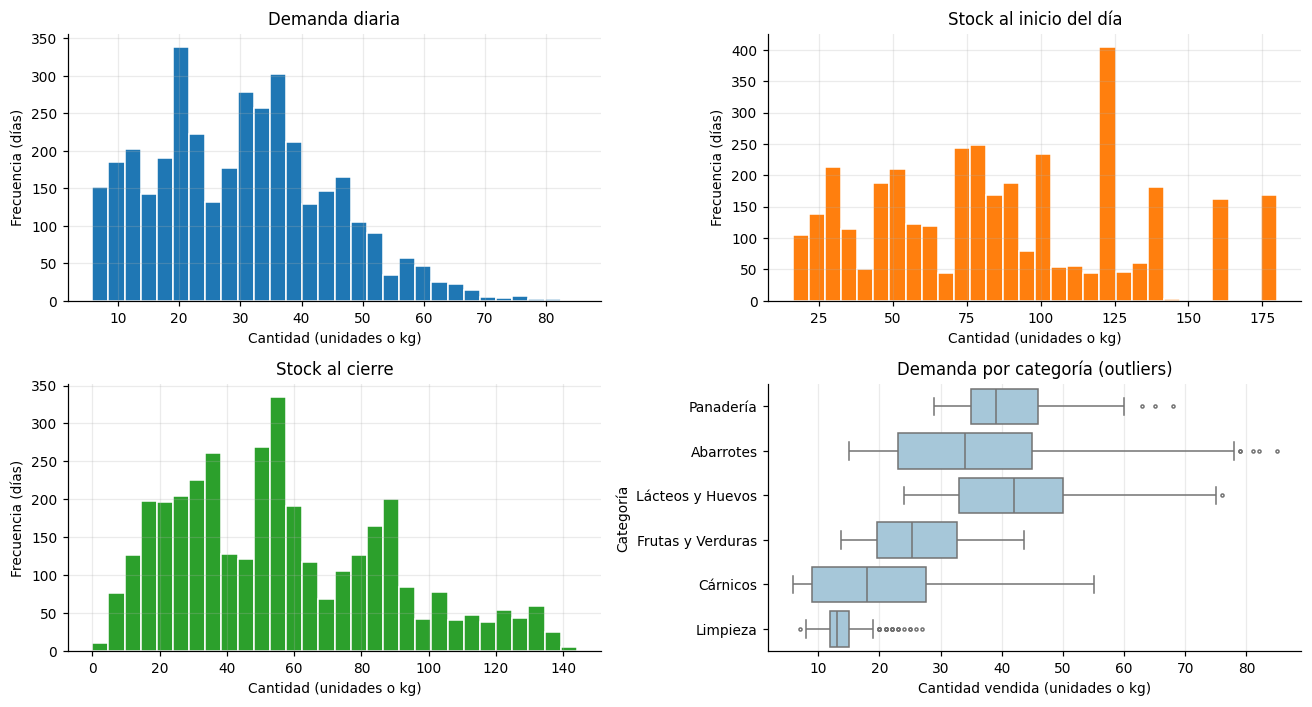

,,media,desviación,outliers (IQR)
product_id,nombre,,,
103665,Pan de Molde Blanco,40.87,7.01,3
105574,Arroz Flor Blanco 1kg,46.94,10.64,13
108634,Leche Entera Tetrapack 1L,51.34,7.49,2
108701,Tomate Riñón Fresco,32.77,3.39,4
114674,Pollo Entero Fresco,30.19,8.25,2
119024,Huevos Blancos Empaque 12u,33.93,4.67,2
121528,Aceite Vegetal Palma 1L,23.60,5.15,12
123601,Manzana Royal Gala,19.72,2.04,8
126938,Detergente Multiuso 1kg,13.84,3.29,29


In [5]:
# Fig 01: distribución de cada variable y outliers por categoría
fig, ejes = plt.subplots(2, 2, figsize=(12, 6.5))
for ax, col, tit, clr in zip(ejes.flat[:3],
                             ["cantidad_vendida", "stock_en_momento", "stock_cierre"],
                             ["Demanda diaria", "Stock al inicio del día", "Stock al cierre"],
                             ["#1f77b4", "#ff7f0e", "#2ca02c"]):
    ax.hist(ventas[col], bins=30, color=clr, edgecolor="white")
    ax.set(title=tit, xlabel="Cantidad (unidades o kg)", ylabel="Frecuencia (días)")
sns.boxplot(data=ventas, x="cantidad_vendida", y="categoria", ax=ejes[1, 1], color="#9ecae1", fliersize=2)
ejes[1, 1].set(title="Demanda por categoría (outliers)", xlabel="Cantidad vendida (unidades o kg)", ylabel="Categoría")
guardar_grafico("01_distribuciones")

# Outliers por producto (regla IQR)
def contar_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())

outliers = ventas.groupby(["product_id", "nombre"])["cantidad_vendida"].agg(["mean", "std", contar_outliers]).round(2)
outliers.columns = ["media", "desviación", "outliers (IQR)"]
display(outliers)

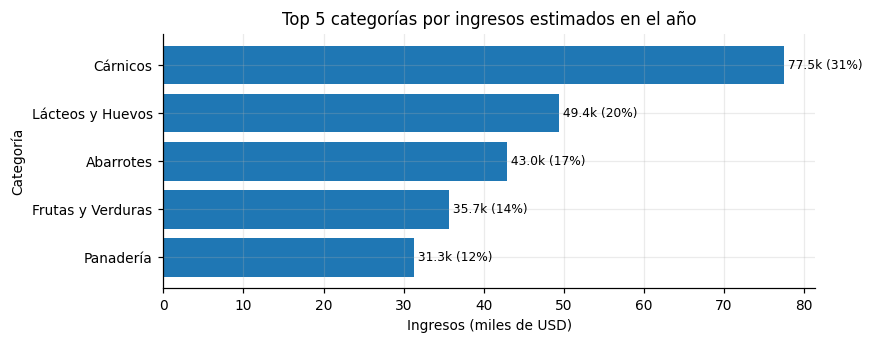

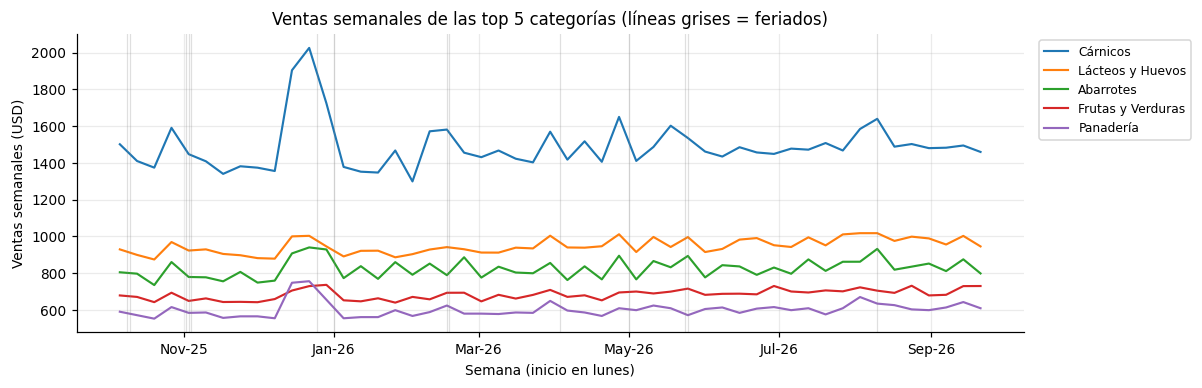

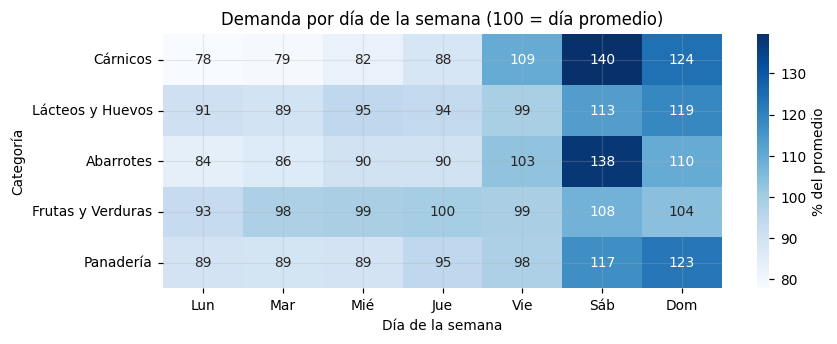

In [6]:
# Fig 02 (E.1): Top 5 categorías por ingresos — ¿dónde está el dinero?
ingreso_cat = ventas.groupby("categoria")["ingreso_usd"].sum().sort_values(ascending=False)
TOP_CATEGORIAS = ingreso_cat.head(5).index.tolist()
top = ingreso_cat.head(5).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(top.index, top.values / 1000, color="#1f77b4")
for i, v in enumerate(top.values / 1000):
    ax.text(v, i, f" {v:,.1f}k ({v * 1000 / ingreso_cat.sum():.0%})", va="center", fontsize=8)
ax.set(title="Top 5 categorías por ingresos estimados en el año", xlabel="Ingresos (miles de USD)", ylabel="Categoría")
guardar_grafico("02_top5_categorias")

# Fig 03 (E.2): ventas semana a semana de las top 5 (solo semanas completas)
semana = ventas["fecha_venta"].dt.to_period("W-SUN").dt.start_time
dias_semana = ventas.groupby(semana)["fecha_venta"].nunique()
completas = dias_semana[dias_semana == 7].index
semanal = (ventas[ventas["categoria"].isin(TOP_CATEGORIAS)]
           .groupby([semana, "categoria"])["ingreso_usd"].sum().unstack().loc[completas])
fig, ax = plt.subplots(figsize=(11, 3.6))
for col in TOP_CATEGORIAS:
    ax.plot(semanal.index, semanal[col], lw=1.4, label=col)
for f in FERIADOS[(FERIADOS >= fechas[0]) & (FERIADOS <= ultima_fecha)]:
    ax.axvline(f, color="grey", alpha=0.25, lw=0.8)
ax.set(title="Ventas semanales de las top 5 categorías (líneas grises = feriados)",
       xlabel="Semana (inicio en lunes)", ylabel="Ventas semanales (USD)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
guardar_grafico("03_ventas_semanales")

# Fig 04 (E.3): mapa de calor día de la semana x categoría (relativo al promedio de cada categoría)
dias_es = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ventas["dia_semana"] = ventas["fecha_venta"].dt.dayofweek
ventas["indice"] = ventas["cantidad_vendida"] / ventas.groupby("product_id")["cantidad_vendida"].transform("mean")
calor = (ventas[ventas["categoria"].isin(TOP_CATEGORIAS)]
         .groupby(["categoria", "dia_semana"])["indice"].mean().unstack().loc[TOP_CATEGORIAS])
calor.columns = dias_es
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.heatmap(calor * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% del promedio"}, ax=ax)
ax.set(title="Demanda por día de la semana (100 = día promedio)", xlabel="Día de la semana", ylabel="Categoría")
guardar_grafico("04_dia_semana_categoria")

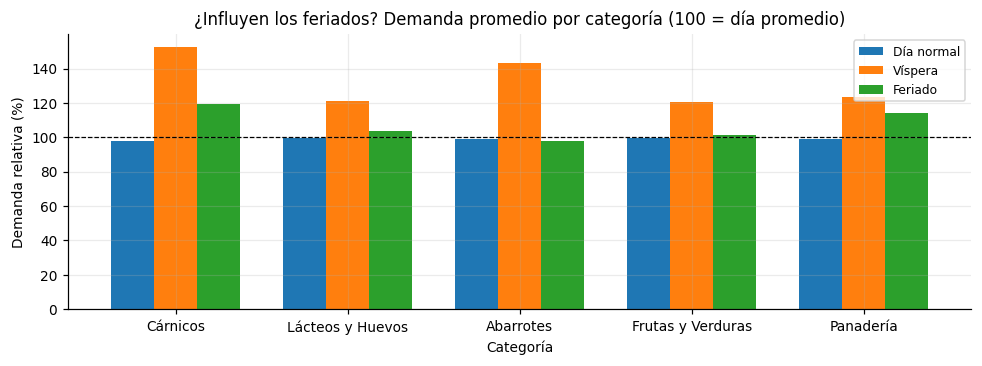

tipo_dia,Día normal,Víspera,Feriado
categoria,,,
Cárnicos,97.8,152.3,119.5
Lácteos y Huevos,99.3,121.0,103.6
Abarrotes,98.9,143.3,98.0
Frutas y Verduras,99.4,120.7,101.4
Panadería,98.8,123.2,114.1


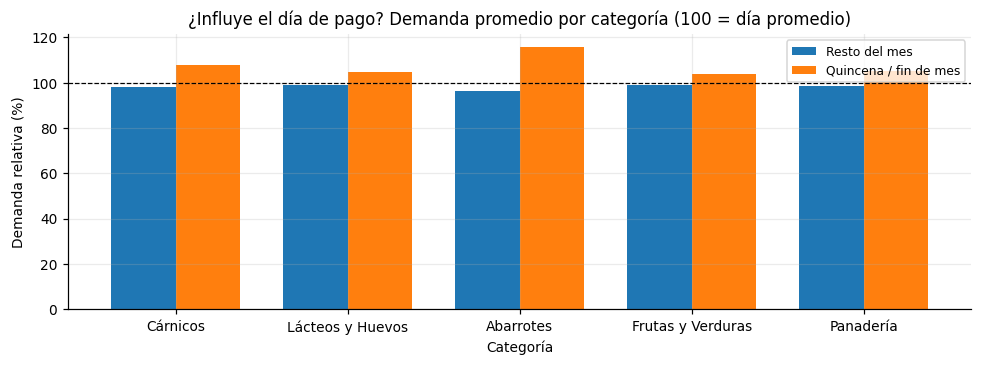

dia_pago,Resto del mes,Quincena / fin de mes
categoria,,
Cárnicos,98.1,107.6
Lácteos y Huevos,98.8,104.7
Abarrotes,96.2,115.6
Frutas y Verduras,99.1,103.8
Panadería,98.7,105.2


In [7]:
# Fig 05 (E.4) y 06 (E.5): feriados y días de pago (100 = día promedio del producto)
ventas["tipo_dia"] = np.select([ventas["fecha_venta"].isin(FERIADOS), ventas["fecha_venta"].isin(VISPERAS)],
                               ["Feriado", "Víspera"], "Día normal")
ventas["dia_pago"] = np.where(es_dia_pago(ventas["fecha_venta"]), "Quincena / fin de mes", "Resto del mes")

for nombre, col, orden, titulo in [
        ("05_feriado_vs_normal", "tipo_dia", ["Día normal", "Víspera", "Feriado"], "¿Influyen los feriados?"),
        ("06_dia_pago", "dia_pago", ["Resto del mes", "Quincena / fin de mes"], "¿Influye el día de pago?")]:
    tabla = (ventas[ventas["categoria"].isin(TOP_CATEGORIAS)]
             .groupby(["categoria", col])["indice"].mean().unstack()[orden].loc[TOP_CATEGORIAS] * 100)
    ax = tabla.plot(kind="bar", figsize=(9, 3.4), width=0.75)
    ax.axhline(100, color="black", lw=0.8, ls="--")
    ax.set(title=f"{titulo} Demanda promedio por categoría (100 = día promedio)",
           xlabel="Categoría", ylabel="Demanda relativa (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="", fontsize=8)
    guardar_grafico(nombre)
    display(tabla.round(1))

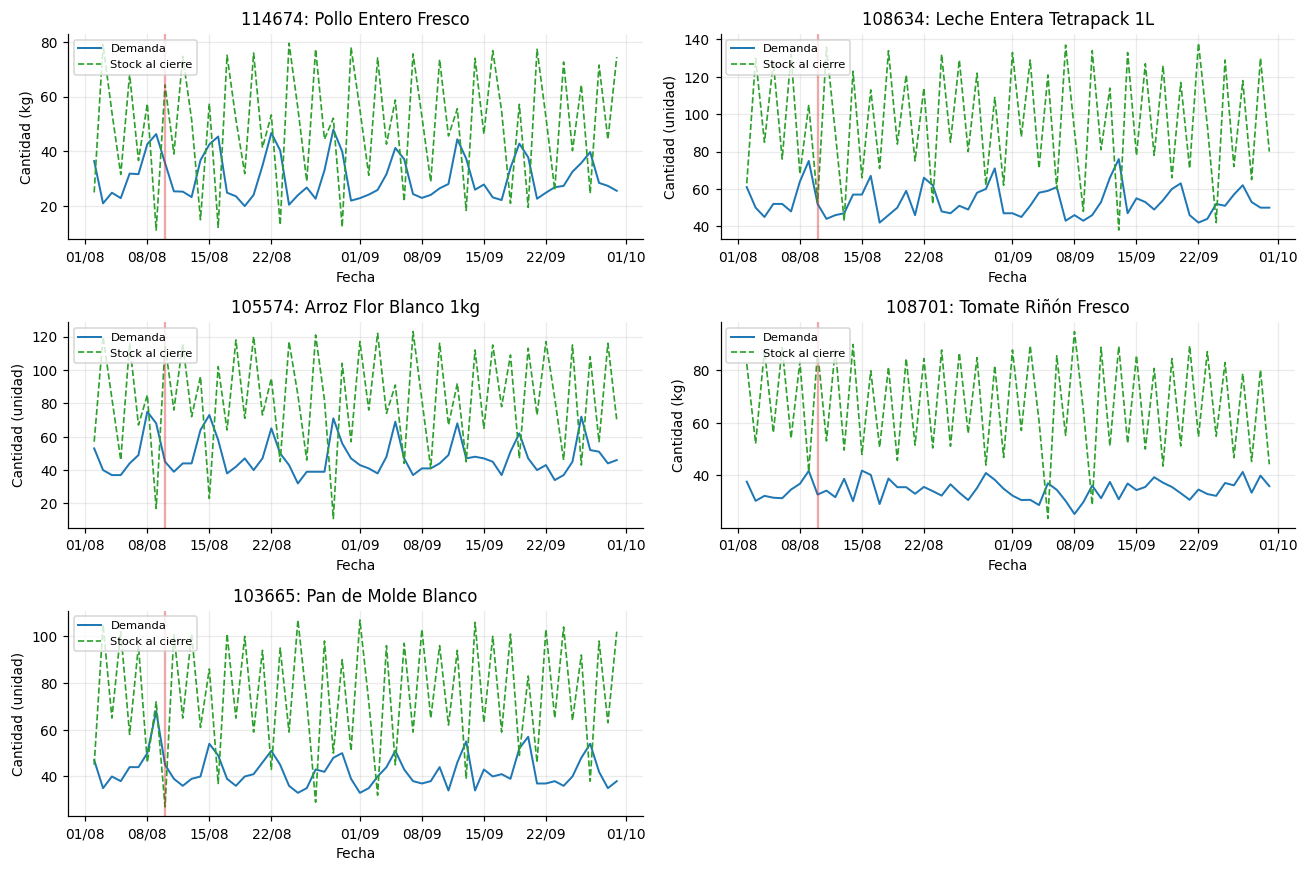

In [8]:
# Fig 07: demanda y stock de los últimos 60 días (un producto por categoría top)
PRODUCTOS_GRAFICO = [inventario.loc[inventario["categoria"] == c, "product_id"].iloc[0] for c in TOP_CATEGORIAS]
recientes = ventas[ventas["fecha_venta"] > ultima_fecha - pd.Timedelta(days=60)]

fig, ejes = plt.subplots(3, 2, figsize=(12, 8), sharex=True)
for ax, cod in zip(ejes.flat, PRODUCTOS_GRAFICO):
    g = recientes[recientes["product_id"] == cod]
    u = PRODUCTOS_INFO[cod]["unidad"]
    ax.plot(g["fecha_venta"], g["cantidad_vendida"], label="Demanda", color="#1f77b4", lw=1.3)
    ax.plot(g["fecha_venta"], g["stock_cierre"], label="Stock al cierre", color="#2ca02c", lw=1.1, ls="--")
    for f in FERIADOS[(FERIADOS >= g["fecha_venta"].min()) & (FERIADOS <= ultima_fecha)]:
        ax.axvline(f, color="#d62728", alpha=0.4)
    ax.set(title=f"{cod}: {PRODUCTOS_INFO[cod]['nombre']}", xlabel="Fecha", ylabel=f"Cantidad ({u})")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.tick_params(labelbottom=True)
    ax.legend(fontsize=7.5, loc="upper left")
ejes.flat[-1].axis("off")
guardar_grafico("07_ultimos_60_dias")

**Conclusiones del EDA:**
- **¿Dónde está el dinero?** Cárnicos genera el 31 % de los ingresos, seguido de Lácteos y Huevos (20 %) y Abarrotes (17 %). Limpieza (6 %) queda fuera del top 5.
- **Fin de semana:** Cárnicos (140 % el sábado) y Abarrotes (138 % el sábado) son los que más suben. Frutas y Verduras se mantiene estable (entre 93 % y 108 %).
- **Feriados:** el efecto más fuerte está en la **víspera**: Cárnicos 152 % y Abarrotes 143 %. El feriado en sí sube solo en Cárnicos (120 %) y Panadería (114 %).
- **Día de pago:** Abarrotes vende 116 % en quincena y fin de mes, frente a 96 % el resto del mes.
- **Temporada:** la segunda quincena de diciembre es el pico del año. Cárnicos llega a unos 2.000 USD por semana, frente a una mediana de 1.470 USD.
- **Outliers:** son picos reales de sábado, víspera o Navidad (por ejemplo, Detergente tiene 29), no errores. Por eso se conservan.

### 2B. Feature Engineering

Cada fila del día *d* lleva el calendario del día siguiente (*d+1*), que es el día a predecir. El calendario se conoce de antemano, así que no hay fuga de datos. El stock entra solo con rezago (cierre del día anterior al objetivo).

In [9]:
COLS_HIST = ["product_id", "fecha_venta", "cantidad_vendida", "stock_cierre"]

def crear_variables(hist, usar_ingenieria=True):
    """Variables de entrada de UN producto. La fila d describe el día d y el calendario de d+1."""
    h = hist.reset_index(drop=True)
    cod = h["product_id"].iloc[0]
    sig = h["fecha_venta"] + pd.Timedelta(days=1)
    X = pd.DataFrame({"cantidad_vendida": h["cantidad_vendida"].astype(float)})
    for c in CODIGOS:                                           # one-hot de producto
        X[f"prod_{c}"] = float(cod == c)
    if usar_ingenieria:
        for c in CATEGORIAS:                                    # one-hot de categoría
            X[f"cat_{c}"] = float(PRODUCTOS_INFO[cod]["categoria"] == c)
        X["stock_dia_anterior"] = h["stock_cierre"].astype(float)
        X["media_movil_7"] = h["cantidad_vendida"].rolling(7).mean()
        X["venta_hace_7_dias"] = h["cantidad_vendida"].shift(6)  # misma día de la semana que d+1
        X["dia_semana"] = sig.dt.dayofweek
        X["mes"] = sig.dt.month
        X["semana_ano"] = sig.dt.isocalendar().week.astype(int)
        X["fin_de_semana"] = (sig.dt.dayofweek >= 5).astype(int)
        X["es_feriado"] = sig.isin(FERIADOS).astype(int)
        X["vispera_feriado"] = sig.isin(VISPERAS).astype(int)
        X["dia_pago"] = es_dia_pago(sig).astype(int)
        X["temporada_navidad"] = es_navidad(sig).astype(int)
    return X.astype("float32")

ejemplo = crear_variables(ventas[ventas["product_id"] == CODIGOS[0]][COLS_HIST])
print(f"Variables por día: {ejemplo.shape[1]}")
display(ejemplo.iloc[6:9].T.head(40))

Variables por día: 28


,6,7,8
cantidad_vendida,34.00000,37.0,42.00000
prod_103665,1.00000,1.0,1.00000
prod_105574,0.00000,0.0,0.00000
prod_108634,0.00000,0.0,0.00000
prod_108701,0.00000,0.0,0.00000
prod_114674,0.00000,0.0,0.00000
prod_119024,0.00000,0.0,0.00000
prod_121528,0.00000,0.0,0.00000
prod_123601,0.00000,0.0,0.00000
prod_126938,0.00000,0.0,0.00000


### 2C. Preparación de secuencias de tiempo

`series_to_supervised` se aplica **por producto**, así una ventana nunca mezcla dos productos. La división train / validación / prueba es **por fechas**, sin barajar, y los escaladores se ajustan **solo con train**.

In [10]:
DIAS_VAL, DIAS_TEST = 30, 30
inicio_test = ultima_fecha - pd.Timedelta(days=DIAS_TEST - 1)
inicio_val = inicio_test - pd.Timedelta(days=DIAS_VAL)
print(f"Train: {fechas[0].date()} a {(inicio_val - pd.Timedelta(days=1)).date()}")
print(f"Val:   {inicio_val.date()} a {(inicio_test - pd.Timedelta(days=1)).date()}")
print(f"Test:  {inicio_test.date()} a {ultima_fecha.date()}")

def series_to_supervised(data, n_in=1):
    """Une los n_in días anteriores como entrada. El índice resultante es la fila del día objetivo."""
    df = pd.DataFrame(data)
    bloques = [df.shift(i) for i in range(n_in, 0, -1)]
    return pd.concat(bloques, axis=1).dropna()

def preparar_secuencias(n_dias, usar_ingenieria, usar_todo=False):
    """Tensores 3D [muestras, días, variables] construidos producto por producto."""
    grupos = {c: g[COLS_HIST].reset_index(drop=True) for c, g in ventas.groupby("product_id")}
    variables = {c: crear_variables(g, usar_ingenieria) for c, g in grupos.items()}
    todas = pd.concat(variables.values(), ignore_index=True)
    fechas_filas = pd.concat([g["fecha_venta"] for g in grupos.values()], ignore_index=True)
    demanda = pd.concat([g[["cantidad_vendida"]] for g in grupos.values()], ignore_index=True)
    ajuste = np.ones(len(todas), bool) if usar_todo else (fechas_filas < inicio_val).to_numpy()
    scaler_X = MinMaxScaler().fit(todas[ajuste])
    scaler_y = MinMaxScaler().fit(demanda[ajuste])

    X, y, metas = [], [], []
    for c, g in grupos.items():
        superv = series_to_supervised(scaler_X.transform(variables[c]), n_in=n_dias)
        idx = superv.index
        X.append(superv.to_numpy("float32").reshape(len(idx), n_dias, todas.shape[1]))
        y.append(scaler_y.transform(g.loc[idx, ["cantidad_vendida"]]).astype("float32"))
        metas.append(g.loc[idx, ["product_id", "fecha_venta", "cantidad_vendida", "stock_cierre"]])
    X, y = np.concatenate(X), np.concatenate(y)
    meta = pd.concat(metas, ignore_index=True)
    mascaras = {"train": (meta["fecha_venta"] < inicio_val).to_numpy(),
                "val": meta["fecha_venta"].between(inicio_val, inicio_test - pd.Timedelta(days=1)).to_numpy(),
                "test": (meta["fecha_venta"] >= inicio_test).to_numpy()}
    return {"X": X, "y": y, "meta": meta, "mascaras": mascaras,
            "scaler_X": scaler_X, "scaler_y": scaler_y, "cols": todas.columns.tolist()}

d7 = preparar_secuencias(7, True)
m = d7["mascaras"]
train_X, train_y = d7["X"][m["train"]], d7["y"][m["train"]]
val_X, val_y = d7["X"][m["val"]], d7["y"][m["val"]]
test_X, test_y = d7["X"][m["test"]], d7["y"][m["test"]]
print(f"\nVentana de 7 días: train_X {train_X.shape}, train_y {train_y.shape}")
print(f"                   val_X {val_X.shape}, val_y {val_y.shape}")
print(f"                   test_X {test_X.shape}, test_y {test_y.shape}")

Train: 2025-10-01 a 2026-08-01
Val:   2026-08-02 a 2026-08-31
Test:  2026-09-01 a 2026-09-30

Ventana de 7 días: train_X (2920, 7, 28), train_y (2920, 1)
                   val_X (300, 7, 28), val_y (300, 1)
                   test_X (300, 7, 28), test_y (300, 1)


## 3. Fase 2: Desarrollo y entrenamiento de modelos

LSTM(50) + Dense(1), pérdida MAE, Adam, `shuffle=False` y EarlyStopping. Se compara el modelo sin Feature Engineering contra el modelo con FE, y la ventana de 3, 7 y 14 días. La elección se hace con el **conjunto de validación**.

LSTM sin FE: 7 días      | RMSE val:  7.805 | mejor época:   4


LSTM con FE: 3 días      | RMSE val:  4.931 | mejor época:  19


LSTM con FE: 7 días      | RMSE val:  4.760 | mejor época:  19


LSTM con FE: 14 días     | RMSE val:  7.095 | mejor época:   6

Modelo seleccionado por validación: LSTM con FE: 7 días


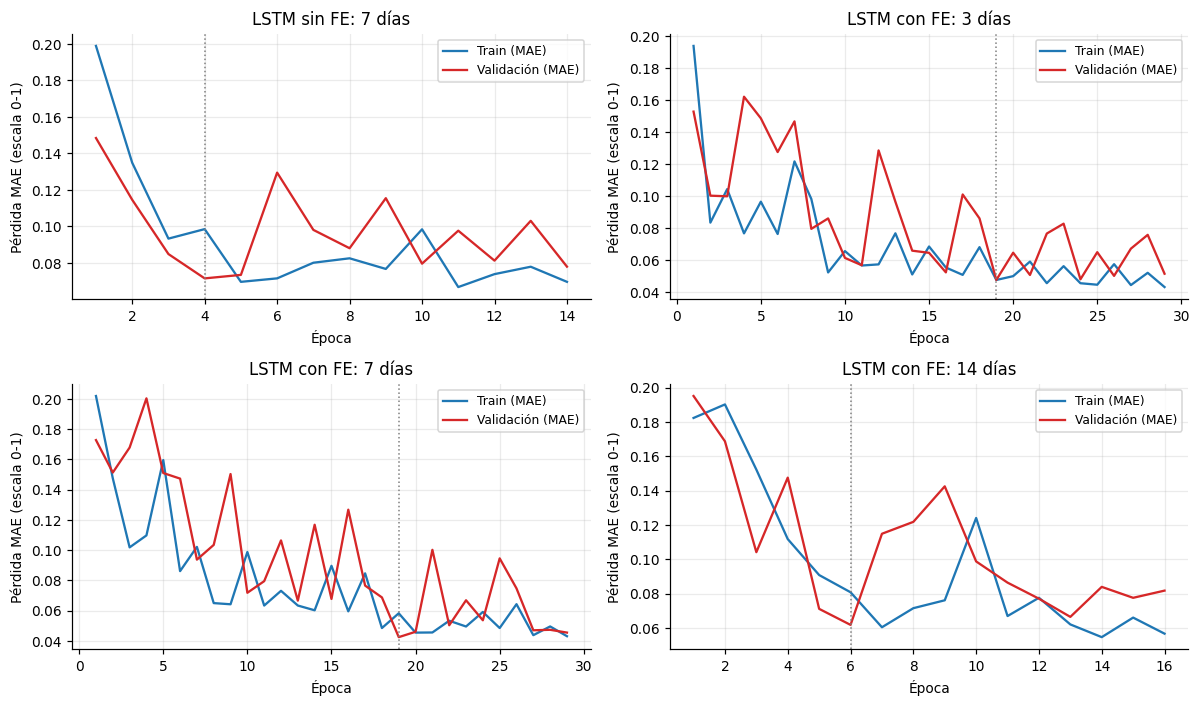

In [11]:
def construir_modelo(n_dias, n_vars):
    tf.keras.utils.set_random_seed(SEMILLA)
    model = Sequential([Input(shape=(n_dias, n_vars)), LSTM(50), Dense(1)])
    model.compile(loss="mae", optimizer="adam", metrics=["mse"])
    return model

def predecir_red(modelo, X, scaler_y):
    """Demanda en escala original (nunca negativa)."""
    norm = modelo(X, training=False).numpy()
    return np.clip(scaler_y.inverse_transform(norm).ravel(), 0, None)

configuraciones = [
    {"nombre": "LSTM sin FE: 7 días", "n_dias": 7, "ingenieria": False},
    {"nombre": "LSTM con FE: 3 días", "n_dias": 3, "ingenieria": True},
    {"nombre": "LSTM con FE: 7 días", "n_dias": 7, "ingenieria": True},
    {"nombre": "LSTM con FE: 14 días", "n_dias": 14, "ingenieria": True},
]

experimentos = []
for cfg in configuraciones:
    d = preparar_secuencias(cfg["n_dias"], cfg["ingenieria"])
    tr, va = d["mascaras"]["train"], d["mascaras"]["val"]
    modelo = construir_modelo(cfg["n_dias"], d["X"].shape[2])
    parada = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    hist = modelo.fit(d["X"][tr], d["y"][tr], validation_data=(d["X"][va], d["y"][va]),
                      epochs=100, batch_size=64, callbacks=[parada], verbose=0, shuffle=False)
    pred_v = predecir_red(modelo, d["X"][va], d["scaler_y"])
    rmse_v = np.sqrt(mean_squared_error(d["meta"].loc[va, "cantidad_vendida"], pred_v))
    mejor_ep = int(np.argmin(hist.history["val_loss"]) + 1)
    experimentos.append({**cfg, "model": modelo, "datos": d, "history": hist, "RMSE_val": rmse_v, "mejor_epoca": mejor_ep})
    print(f"{cfg['nombre']:24s} | RMSE val: {rmse_v:6.3f} | mejor época: {mejor_ep:3d}")

seleccionado = min(experimentos, key=lambda e: e["RMSE_val"])
print(f"\nModelo seleccionado por validación: {seleccionado['nombre']}")

# Fig 08: curvas de pérdida train vs val
fig, ejes = plt.subplots(2, 2, figsize=(11, 6.5))
for ax, e in zip(ejes.flat, experimentos):
    h = e["history"].history
    ax.plot(range(1, len(h["loss"]) + 1), h["loss"], label="Train (MAE)", color="#1f77b4")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="Validación (MAE)", color="#d62728")
    ax.axvline(e["mejor_epoca"], color="grey", ls=":", lw=1)
    ax.set(title=e["nombre"], xlabel="Época", ylabel="Pérdida MAE (escala 0-1)")
    ax.legend(fontsize=8)
guardar_grafico("08_curvas_entrenamiento")

### 3.1 Evaluación en prueba y comparación con líneas base

Métricas en la **escala original** (unidades o kg). El stock se calcula con la demanda predicha: `stock_cierre = max(stock_inicio − demanda, 0)`. El stock al inicio del día se conoce por la regla de reposición.

,Modelo,Ventana (días),RMSE val,RMSE demanda,MAE demanda,RMSE stock,Mejor época
0,LSTM sin FE: 7 días,7.0,7.805,6.721,5.034,6.715,4.0
1,LSTM con FE: 3 días,3.0,4.931,4.802,3.643,4.802,19.0
2,LSTM con FE: 7 días,7.0,4.760,4.400,3.103,4.400,19.0
3,LSTM con FE: 14 días,14.0,7.095,6.357,4.327,6.357,6.0
4,Base: persistencia (venta de ayer),NaN,NaN,6.467,4.505,6.467,NaN
5,Base: promedio móvil 7 días,NaN,NaN,5.643,4.106,5.643,NaN
6,Base: mismo día semana anterior,NaN,NaN,4.391,3.294,4.391,NaN
7,Base: stock de ayer (persistencia de stock),NaN,NaN,NaN,NaN,36.896,NaN


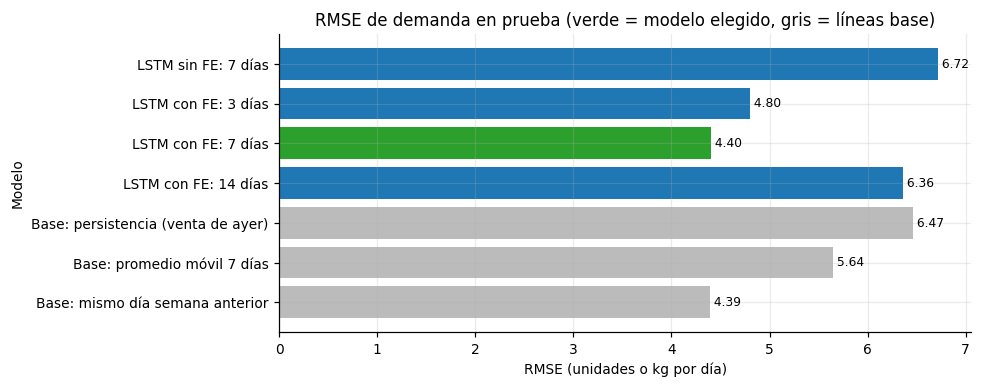

In [12]:
prueba = ventas[ventas["fecha_venta"] >= inicio_test]
def rmse(real, pred):
    return float(np.sqrt(mean_squared_error(real, pred)))

filas, preds_test = [], {}
for e in experimentos:
    d = e["datos"]
    te = d["mascaras"]["test"]
    meta = d["meta"].loc[te].reset_index(drop=True)
    meta["demanda_pred"] = predecir_red(e["model"], d["X"][te], d["scaler_y"])
    meta = meta.merge(prueba[["product_id", "fecha_venta", "stock_en_momento"]], on=["product_id", "fecha_venta"])
    meta["stock_pred"] = (meta["stock_en_momento"] - meta["demanda_pred"]).clip(lower=0)
    preds_test[e["nombre"]] = meta
    filas.append({"Modelo": e["nombre"], "Ventana (días)": e["n_dias"], "RMSE val": e["RMSE_val"],
                  "RMSE demanda": rmse(meta["cantidad_vendida"], meta["demanda_pred"]),
                  "MAE demanda": mean_absolute_error(meta["cantidad_vendida"], meta["demanda_pred"]),
                  "RMSE stock": rmse(meta["stock_cierre"], meta["stock_pred"]),
                  "Mejor época": e["mejor_epoca"]})

# Líneas base sobre los mismos días de prueba
v = ventas.copy()
g = v.groupby("product_id")["cantidad_vendida"]
v["persistencia"] = g.shift(1)
v["promedio_movil_7"] = g.transform(lambda s: s.shift(1).rolling(7).mean())
v["semana_anterior"] = g.shift(7)
v["stock_ayer"] = v.groupby("product_id")["stock_cierre"].shift(1)
bt = v[v["fecha_venta"] >= inicio_test]
for nombre, col in [("Base: persistencia (venta de ayer)", "persistencia"),
                    ("Base: promedio móvil 7 días", "promedio_movil_7"),
                    ("Base: mismo día semana anterior", "semana_anterior")]:
    stock_b = (bt["stock_en_momento"] - bt[col]).clip(lower=0)
    filas.append({"Modelo": nombre, "Ventana (días)": np.nan, "RMSE val": np.nan,
                  "RMSE demanda": rmse(bt["cantidad_vendida"], bt[col]),
                  "MAE demanda": mean_absolute_error(bt["cantidad_vendida"], bt[col]),
                  "RMSE stock": rmse(bt["stock_cierre"], stock_b), "Mejor época": np.nan})
filas.append({"Modelo": "Base: stock de ayer (persistencia de stock)", "RMSE stock": rmse(bt["stock_cierre"], bt["stock_ayer"])})

tabla_metricas = pd.DataFrame(filas)
tabla_metricas.to_csv(TABLAS / "metricas_modelos.csv", index=False)
display(tabla_metricas.round(3))

# Fig 09: comparación del RMSE de demanda
t = tabla_metricas.dropna(subset=["RMSE demanda"])
colores = ["#2ca02c" if n == seleccionado["nombre"] else ("#1f77b4" if not n.startswith("Base:") else "#bbbbbb") for n in t["Modelo"]]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(t["Modelo"], t["RMSE demanda"], color=colores)
for i, val in enumerate(t["RMSE demanda"]):
    ax.text(val, i, f" {val:.2f}", va="center", fontsize=8)
ax.invert_yaxis()
ax.set(title="RMSE de demanda en prueba (verde = modelo elegido, gris = líneas base)",
       xlabel="RMSE (unidades o kg por día)", ylabel="Modelo")
guardar_grafico("09_comparacion_modelos")

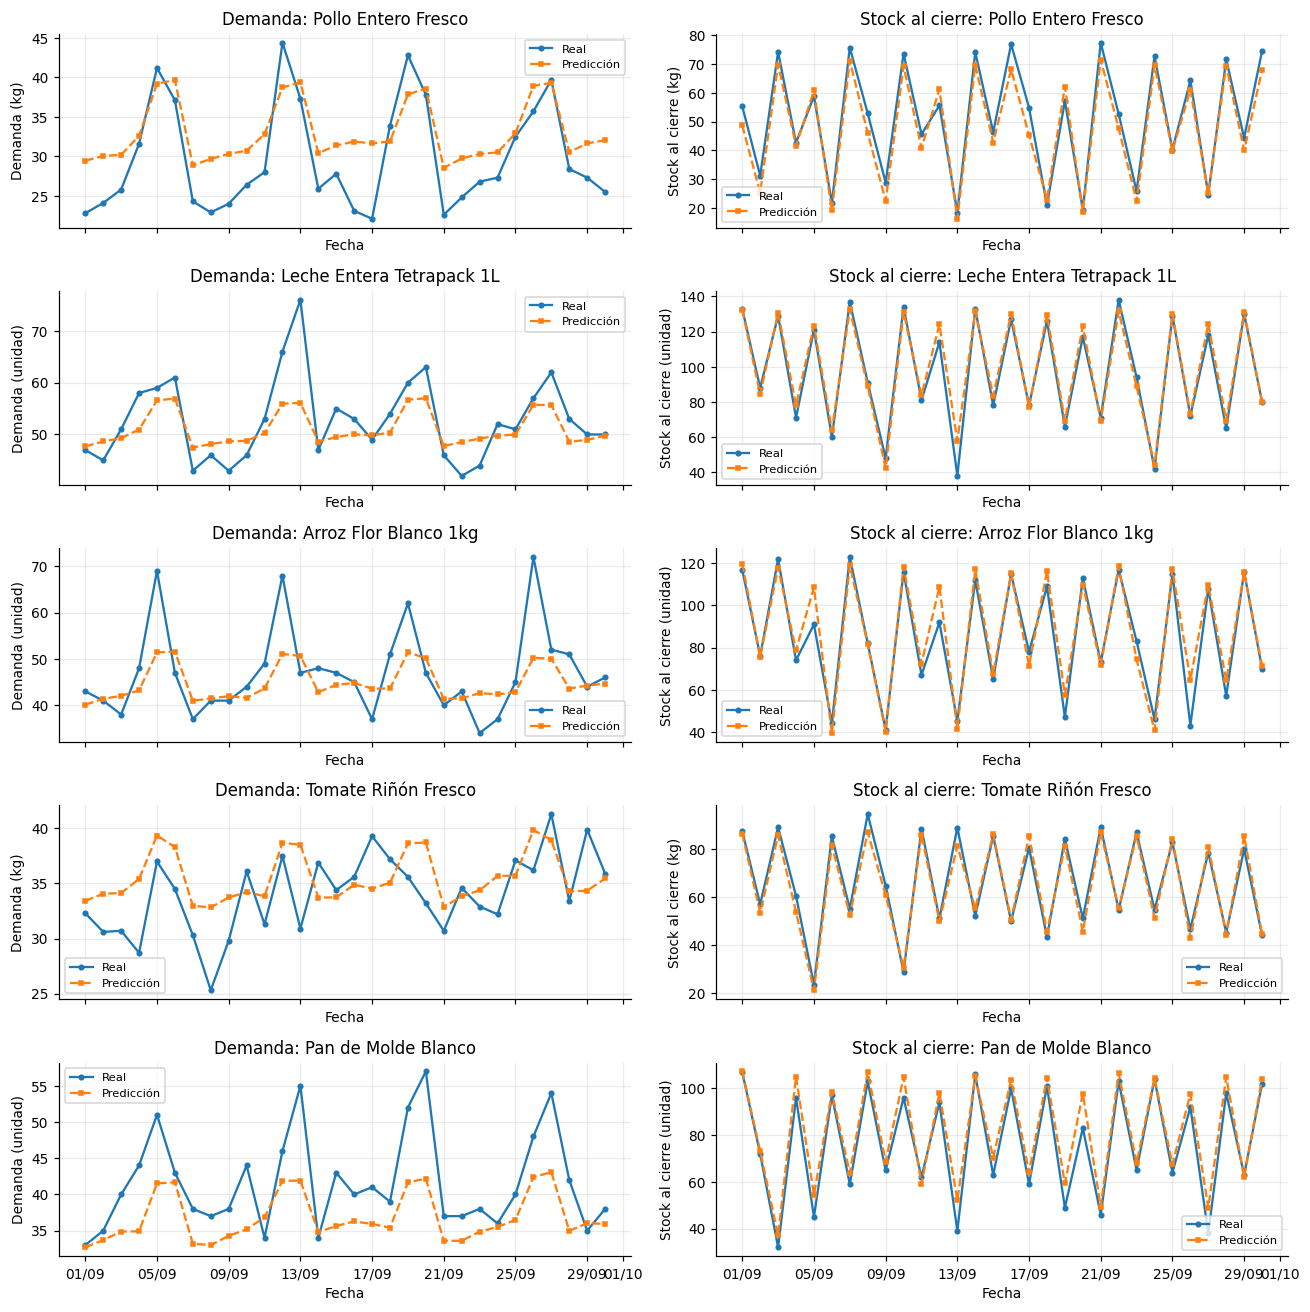

In [13]:
# Fig 10: predicción vs real en prueba (demanda y stock)
sel = preds_test[seleccionado["nombre"]]
fig, ejes = plt.subplots(len(PRODUCTOS_GRAFICO), 2, figsize=(12, 2.4 * len(PRODUCTOS_GRAFICO)), sharex=True)
for fila, cod in zip(ejes, PRODUCTOS_GRAFICO):
    g = sel[sel["product_id"] == cod]
    u = PRODUCTOS_INFO[cod]["unidad"]
    for ax, real, pred, que in [(fila[0], "cantidad_vendida", "demanda_pred", "Demanda"),
                                (fila[1], "stock_cierre", "stock_pred", "Stock al cierre")]:
        ax.plot(g["fecha_venta"], g[real], "o-", ms=3, label="Real", color="#1f77b4")
        ax.plot(g["fecha_venta"], g[pred], "s--", ms=3, label="Predicción", color="#ff7f0e")
        ax.set(title=f"{que}: {PRODUCTOS_INFO[cod]['nombre']}", xlabel="Fecha", ylabel=f"{que} ({u})")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
        ax.legend(fontsize=7.5)
guardar_grafico("10_prediccion_vs_real")

### 3.2 Modelo final y guardado de artefactos

In [14]:
# Reentrenar con todo el historial usando la configuración y épocas elegidas
N_DIAS = seleccionado["n_dias"]
USAR_INGENIERIA = seleccionado["ingenieria"]
datos_final = preparar_secuencias(N_DIAS, USAR_INGENIERIA, usar_todo=True)
scaler_X, scaler_y = datos_final["scaler_X"], datos_final["scaler_y"]

modelo_final = construir_modelo(N_DIAS, datos_final["X"].shape[2])
modelo_final.fit(datos_final["X"], datos_final["y"], epochs=seleccionado["mejor_epoca"],
                 batch_size=64, verbose=0, shuffle=False)

modelo_final.save(MODELOS / "demanda_lstm.keras")
joblib.dump({"X": scaler_X, "y": scaler_y}, MODELOS / "escaladores.joblib")
config = {
    "modelo": seleccionado["nombre"], "n_dias": N_DIAS, "ingenieria": USAR_INGENIERIA,
    "epocas": seleccionado["mejor_epoca"], "columnas": datos_final["cols"],
    "ultima_fecha": ultima_fecha.strftime("%Y-%m-%d"), "horizonte_max_dias": HORIZONTE_MAX,
    "codigos": CODIGOS, "productos_info": PRODUCTOS_INFO,
    "politica_reposicion": {c: {"punto_reorden": s, "nivel_maximo": S} for c, (s, S) in POLITICA.items()},
}
(MODELOS / "configuracion.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

# Comprobar que el modelo guardado se recupera igual
recuperado = load_model(MODELOS / "demanda_lstm.keras")
assert np.allclose(recuperado(datos_final["X"][:20]).numpy(), modelo_final(datos_final["X"][:20]).numpy(), atol=1e-5)
print(f"Modelo final guardado: {seleccionado['nombre']} | {seleccionado['mejor_epoca']} épocas | {len(datos_final['X'])} secuencias")

Modelo final guardado: LSTM con FE: 7 días | 19 épocas | 3520 secuencias


## 4. Fase 3: Funciones de predicción

- `predecir_demanda(product_id, fecha)` y `predecir_demanda_todos(fecha)`
- `predecir_stock(product_id, fecha)` y `predecir_stock_todos(fecha)`

Devuelven solo el número: `int` para productos por unidad y `float` para productos por kg. Las listas siguen el orden de `CODIGOS`.

**Limitación:** si la fecha está a más de un día del último dato, la predicción es **recursiva**: cada día predicho se usa como historia del siguiente, así que el error se acumula. Por eso el máximo es de 60 días.

In [15]:
def _validar_producto(product_id):
    if not isinstance(product_id, str) or product_id not in CODIGOS:
        raise ValueError(f"product_id '{product_id}' no existe. Válidos: {', '.join(CODIGOS)}")

def _validar_fecha(fecha):
    if not isinstance(fecha, str) or re.fullmatch(r"\d{4}-\d{2}-\d{2}", fecha) is None:
        raise ValueError("La fecha debe ser un texto con formato YYYY-MM-DD.")
    try:
        objetivo = pd.Timestamp(fecha)
    except ValueError as e:
        raise ValueError(f"La fecha {fecha} no existe.") from e
    primera, limite = ultima_fecha + pd.Timedelta(days=1), ultima_fecha + pd.Timedelta(days=HORIZONTE_MAX)
    if not primera <= objetivo <= limite:
        raise ValueError(f"La fecha debe estar entre {primera.date()} y {limite.date()} (máximo {HORIZONTE_MAX} días).")
    return objetivo

@lru_cache(maxsize=1)
def _pronostico_60_dias():
    """Pronóstico recursivo de TODOS los productos para los 60 días siguientes.
    Una sola llamada a la red por día para los 10 productos; se calcula una vez y se reutiliza."""
    historia = {c: g[COLS_HIST].reset_index(drop=True) for c, g in ventas.groupby("product_id")}
    filas = []
    for dia in pd.date_range(ultima_fecha + pd.Timedelta(days=1), periods=HORIZONTE_MAX, freq="D"):
        X_dia = np.stack([scaler_X.transform(crear_variables(historia[c].tail(N_DIAS + 7), USAR_INGENIERIA))[-N_DIAS:]
                          for c in CODIGOS]).astype("float32")
        demandas = predecir_red(modelo_final, X_dia, scaler_y)
        for c, dem in zip(CODIGOS, demandas):
            reorden, maximo = POLITICA[c]
            cierre_ant = historia[c]["stock_cierre"].iloc[-1]
            stock_ini = maximo if cierre_ant < reorden else cierre_ant
            cierre = max(stock_ini - dem, 0.0)
            nueva = pd.DataFrame([{"product_id": c, "fecha_venta": dia,
                                   "cantidad_vendida": min(dem, stock_ini), "stock_cierre": cierre}])
            historia[c] = pd.concat([historia[c], nueva], ignore_index=True)
            filas.append({"fecha": dia, "product_id": c, "demanda": dem, "stock_cierre": cierre})
    return pd.DataFrame(filas).set_index(["fecha", "product_id"])

def _formatear(valor, product_id):
    """int para productos por unidad, float para productos por kg."""
    if PRODUCTOS_INFO[product_id]["unidad"] == "unidad":
        return int(round(valor))
    return round(float(valor), 2)

def _consultar(product_ids, fecha, columna):
    objetivo = _validar_fecha(fecha)
    for c in product_ids:
        _validar_producto(c)
    resultado = _pronostico_60_dias()
    return [_formatear(resultado.loc[(objetivo, c), columna], c) for c in product_ids]

def predecir_demanda(product_id, fecha):
    """Demanda esperada de un producto en una fecha."""
    return _consultar([product_id], fecha, "demanda")[0]

def predecir_demanda_todos(fecha):
    """Lista con la demanda de todos los productos (orden de CODIGOS)."""
    return _consultar(CODIGOS, fecha, "demanda")

def predecir_stock(product_id, fecha):
    """Stock esperado al cierre de un producto en una fecha."""
    return _consultar([product_id], fecha, "stock_cierre")[0]

def predecir_stock_todos(fecha):
    """Lista con el stock al cierre de todos los productos (orden de CODIGOS)."""
    return _consultar(CODIGOS, fecha, "stock_cierre")

### 4.1 Pruebas de las funciones

In [16]:
manana = (ultima_fecha + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
en_30_dias = (ultima_fecha + pd.Timedelta(days=30)).strftime("%Y-%m-%d")

print("Un producto:")
print(f"  predecir_demanda('114674', '{manana}') = {predecir_demanda('114674', manana)}  (kg -> float)")
print(f"  predecir_demanda('103665', '{manana}') = {predecir_demanda('103665', manana)}  (unidad -> int)")
print(f"  predecir_stock('114674', '{en_30_dias}') = {predecir_stock('114674', en_30_dias)}  (recursivo, 30 días)")

print("\nTodos los productos:")
print(f"  predecir_demanda_todos('{manana}') = {predecir_demanda_todos(manana)}")
print(f"  predecir_stock_todos('{manana}')   = {predecir_stock_todos(manana)}")

# Coherencia: la lista coincide con las consultas individuales
for fecha in (manana, en_30_dias):
    assert predecir_demanda_todos(fecha) == [predecir_demanda(c, fecha) for c in CODIGOS]
    assert predecir_stock_todos(fecha) == [predecir_stock(c, fecha) for c in CODIGOS]
assert all(isinstance(predecir_demanda(c, manana), int if PRODUCTOS_INFO[c]["unidad"] == "unidad" else float) for c in CODIGOS)
print("\nCoherencia individual vs. todos: OK")

# Entradas inválidas
fuera = (ultima_fecha + pd.Timedelta(days=HORIZONTE_MAX + 1)).strftime("%Y-%m-%d")
for args in [("999999", manana), ("114674", "2026-13-01"), ("114674", fuera), ("114674", "2026-09-15")]:
    try:
        predecir_demanda(*args)
        print(f"  {args}: NO se rechazó")
    except ValueError as e:
        print(f"  {args}: rechazado -> {e}")

Un producto:


  predecir_demanda('114674', '2026-10-01') = 33.23  (kg -> float)
  predecir_demanda('103665', '2026-10-01') = 39  (unidad -> int)
  predecir_stock('114674', '2026-10-30') = 61.64  (recursivo, 30 días)

Todos los productos:
  predecir_demanda_todos('2026-10-01') = [39, 43, 51, 36.08, 33.23, 40, 30, 24.05, 14, 10.46]
  predecir_stock_todos('2026-10-01')   = [63, 117, 129, 83.92, 41.27, 44, 24, 47.95, 20, 12.74]

Coherencia individual vs. todos: OK
  ('999999', '2026-10-01'): rechazado -> product_id '999999' no existe. Válidos: 103665, 105574, 108634, 108701, 114674, 119024, 121528, 123601, 126938, 135432
  ('114674', '2026-13-01'): rechazado -> La fecha 2026-13-01 no existe.
  ('114674', '2026-11-30'): rechazado -> La fecha debe estar entre 2026-10-01 y 2026-11-29 (máximo 60 días).
  ('114674', '2026-09-15'): rechazado -> La fecha debe estar entre 2026-10-01 y 2026-11-29 (máximo 60 días).


## 5. Predicciones personalizadas

Edita las variables al inicio de la celda. Para un mes completo, usa el primer y el último día del mes. Máximo 60 días después del último dato (hasta el 29/11/2026).

producto,Lomo Fino de Res,Pan de Molde Blanco,Pollo Entero Fresco,Tomate Riñón Fresco
fecha,,,,
2026-10-01,10.46,39.0,33.23,36.08
2026-10-02,11.19,40.0,34.46,37.19
2026-10-03,15.22,48.0,42.37,41.42
2026-10-04,15.94,48.0,42.47,42.41
2026-10-05,9.05,37.0,30.69,34.62
2026-10-06,8.63,36.0,30.53,35.82
2026-10-07,9.96,38.0,32.25,36.01
2026-10-08,16.49,46.0,41.84,43.52
2026-10-09,15.82,44.0,39.72,40.11


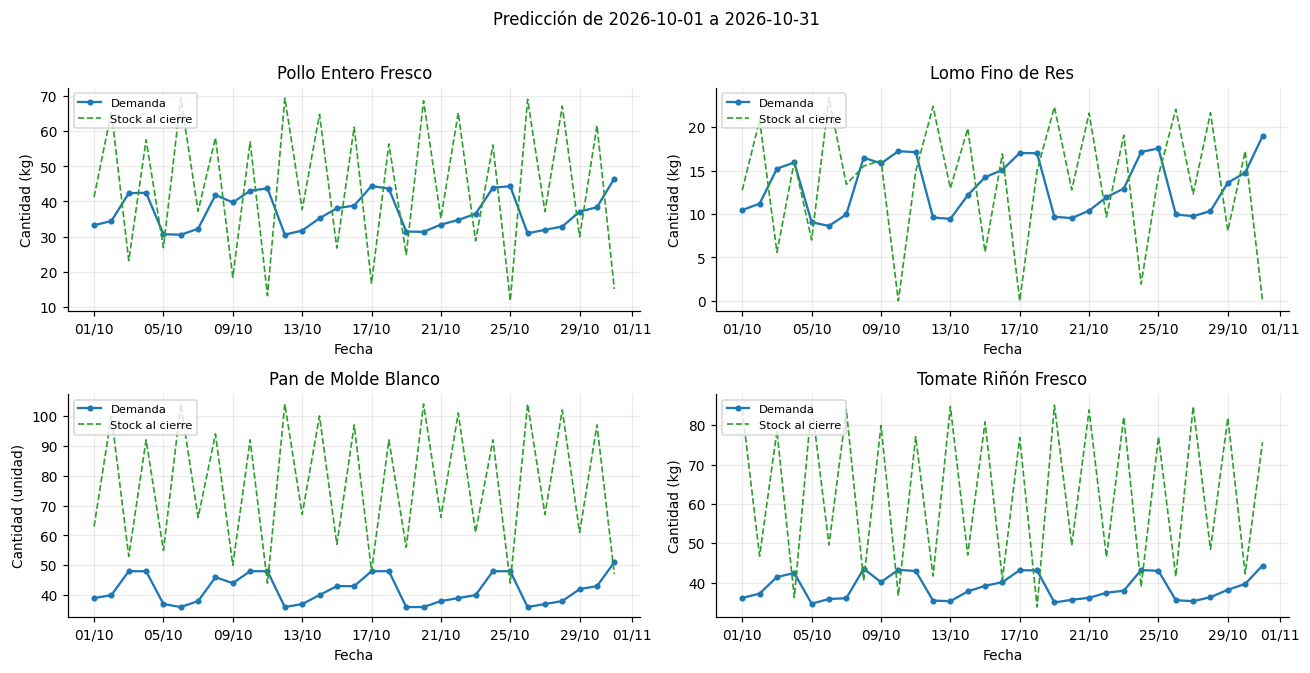

In [17]:
# ===== Variables editables =====
PRODUCTOS_CONSULTA = ["114674", "135432", "103665", "108701"]   # Pollo, Lomo, Pan, Tomate
FECHA_INICIO_CONSULTA = "2026-10-01"
FECHA_FIN_CONSULTA = "2026-10-31"
# ================================

filas = []
for f in pd.date_range(FECHA_INICIO_CONSULTA, FECHA_FIN_CONSULTA, freq="D"):
    f_txt = f.strftime("%Y-%m-%d")
    for c in PRODUCTOS_CONSULTA:
        filas.append({"fecha": f_txt, "product_id": c, "producto": PRODUCTOS_INFO[c]["nombre"],
                      "unidad": PRODUCTOS_INFO[c]["unidad"],
                      "demanda": predecir_demanda(c, f_txt), "stock_cierre": predecir_stock(c, f_txt)})
consulta = pd.DataFrame(filas)
consulta.to_csv(TABLAS / "predicciones_personalizadas.csv", index=False)
display(consulta.pivot(index="fecha", columns="producto", values="demanda").head(10))

# Un panel por producto: demanda y stock predichos
n_filas = int(np.ceil(len(PRODUCTOS_CONSULTA) / 2))
fig, ejes = plt.subplots(n_filas, 2, figsize=(12, 3 * n_filas), squeeze=False)
for ax, c in zip(ejes.flat, PRODUCTOS_CONSULTA):
    g = consulta[consulta["product_id"] == c]
    u = PRODUCTOS_INFO[c]["unidad"]
    ax.plot(pd.to_datetime(g["fecha"]), g["demanda"], marker="o", ms=3, label="Demanda", color="#1f77b4")
    ax.plot(pd.to_datetime(g["fecha"]), g["stock_cierre"], ls="--", lw=1.1, label="Stock al cierre", color="#2ca02c")
    ax.set(title=f"{PRODUCTOS_INFO[c]['nombre']}", xlabel="Fecha", ylabel=f"Cantidad ({u})")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
    ax.legend(fontsize=7.5, loc="upper left")
for ax in ejes.flat[len(PRODUCTOS_CONSULTA):]:
    ax.axis("off")
fig.suptitle(f"Predicción de {FECHA_INICIO_CONSULTA} a {FECHA_FIN_CONSULTA}", y=1.01)
guardar_grafico("11_prediccion_personalizada")

## 6. Conclusiones

1. **Mejor modelo:** LSTM con Feature Engineering y ventana de 7 días. Tiene el menor error en validación (RMSE 4,76) y en prueba obtiene **RMSE 4,40 y MAE 3,10** unidades/kg por día.
2. **Feature Engineering:** con la misma ventana de 7 días, el RMSE baja de 6,72 (sin FE) a 4,40 (con FE), un 35 % menos. Las variables de calendario (fin de semana, víspera, día de pago) son las que explican la demanda.
3. **Líneas base:** el modelo supera a la persistencia (6,47) y al promedio móvil de 7 días (5,64). Frente a "repetir la venta del mismo día de la semana anterior" queda **prácticamente empatado** en RMSE (4,40 frente a 4,39), aunque con menor MAE (3,10 frente a 3,29). La LSTM suaviza los picos de fin de semana y feriado: es lo siguiente a mejorar con el fine-tuning.
4. **Stock:** se calcula desde la demanda con la regla de reposición, así que su error es el mismo que el de la demanda (RMSE 4,40). Usar el "stock de ayer" da un RMSE de 36,90, porque la reposición genera saltos.
5. **Uso:** las funciones predicen demanda y stock hasta 60 días adelante. Por ejemplo, anticipan quiebres del Lomo Fino de Res en octubre de 2026.
6. **Limitaciones:** los datos son sintéticos y de una sola tienda. No se modelan precios ni promociones. La Navidad aparece una sola vez en el entrenamiento. La regla de reposición se supone conocida. En la predicción recursiva el error crece con los días, por eso el límite de 60 días.

## 7. Referencias

1. Bishop, C. M. (2006). *Pattern recognition and machine learning*. Springer.
2. Joshi, P. (2017). *Artificial intelligence with Python*. Packt Publishing.
3. Keras. *LSTM layer*. https://keras.io/api/layers/recurrent_layers/lstm/
4. TensorFlow. *tf.keras.layers.LSTM*. https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM
5. Dingdong-Inc. *FreshRetailNet-50K* [Dataset]. Hugging Face. https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K
6. Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780.
7. Librería `holidays` (feriados de Ecuador). https://pypi.org/project/holidays/